## Data & Analytics - Proyecto Final
Ana Lucía Palacios De La Borda

## Caso de uso

HR Analytics: https://datahack.analyticsvidhya.com/contest/wns-analytics-hackathon-2018-1/

## Importación de librerías

In [106]:
import os
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

seed = 2020
sns.set()

Se utiliza la librería warnings para evitar que se muestren alertas al crear nuevas columnas

In [107]:
import warnings
warnings.filterwarnings('ignore')

In [108]:
pd.__version__

'2.3.3'

In [109]:
np.__version__

'2.3.5'

In [110]:
sklearn.__version__

'1.7.2'

## Lectura de datos

In [111]:
df_hr = pd.read_csv('hr_analytics.csv')

In [112]:
df_hr.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0


In [113]:
id_columns = 'employee_id'
target = 'is_promoted'

## Exploración

In [114]:
df_hr.shape

(54808, 14)

In [115]:
df_hr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  KPIs_met >80%         54808 non-null  int64  
 11  awards_won?           54808 non-null  int64  
 12  avg_training_score    54808 non-null  int64  
 13  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.9+ MB


## Valores nulos

Cuenta y porcentaje de nulos

In [11]:
#El dataset completo tiene 54808 registros

In [116]:
df_hr.isnull().sum()

employee_id                0
department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64

In [117]:
df_hr.isnull().mean()*100

employee_id             0.000000
department              0.000000
region                  0.000000
education               4.395344
gender                  0.000000
recruitment_channel     0.000000
no_of_trainings         0.000000
age                     0.000000
previous_year_rating    7.524449
length_of_service       0.000000
KPIs_met >80%           0.000000
awards_won?             0.000000
avg_training_score      0.000000
is_promoted             0.000000
dtype: float64

Descriptivos de numéricas

In [118]:
df_hr.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,50684.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.329256,5.865512,0.351974,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.259993,4.265094,0.477590,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,1.000000,99.000000,1.000000


Descriptivos de categóricas

In [119]:
df_hr.describe(include='object')

,department,region,education,gender,recruitment_channel
count,54808,54808,52399,54808,54808
unique,9,34,3,2,3
top,Sales & Marketing,region_2,Bachelor's,m,other
freq,16840,12343,36669,38496,30446


In [16]:
#Cantidad de valores únicos - frecuencia de la variable top

Cuentas de valores únicos en variables categóricas

In [120]:
df_hr['education'].value_counts()

education
Bachelor's          36669
Master's & above    14925
Below Secondary       805
Name: count, dtype: int64

In [18]:
#Columna problema para entrenar

In [121]:
df_hr['region'].value_counts()

region
region_2     12343
region_22     6428
region_7      4843
region_15     2808
region_13     2648
region_26     2260
region_31     1935
region_4      1703
region_27     1659
region_16     1465
region_28     1318
region_11     1315
region_23     1175
region_29      994
region_32      945
region_19      874
region_20      850
region_14      827
region_25      819
region_17      796
region_5       766
region_6       690
region_30      657
region_8       655
region_10      648
region_1       610
region_24      508
region_12      500
region_9       420
region_21      411
region_3       346
region_34      292
region_33      269
region_18       31
Name: count, dtype: int64

## Proporción de target

`value_counts()`

In [122]:
target

'is_promoted'

In [123]:
df_hr[target].value_counts()

is_promoted
0    50140
1     4668
Name: count, dtype: int64

`mean()`

Proporción de target

In [124]:
df_hr[target].mean()

np.float64(0.08517004816815063)

In [23]:
#Sólo el 8% han ascendido

# Preprocesamiento

## Train y Test

In [129]:
df_hr.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0


In [130]:
X = df_hr.drop(target, axis = 1).drop(id_columns, axis = 1)
y = df_hr[target]

In [131]:
X.head()

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
0,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49
1,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60
2,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50
3,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50
4,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73


In [132]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: is_promoted, dtype: int64

In [133]:
from sklearn.model_selection import train_test_split

In [134]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, stratify = y, random_state = seed)

ratio de target en train y val

In [135]:
X_train.shape, y_train.shape

((43846, 12), (43846,))

In [136]:
X_test.shape, y_test.shape

((10962, 12), (10962,))

In [137]:
y_train.mean(), y_test.mean()

(np.float64(0.08516170232176254), np.float64(0.08520343003101624))

In [138]:
#8.5% : Controlamos la estrateficación para dividir en test y train

## Imputación de datos

Vamos a imputar los valores nulos

* En el caso de las variables continuas imputamos con la mediana
* En el caso de las variables categóricas imputamos con la moda

In [139]:
X_train.head(2)

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
35058,Operations,region_15,Bachelor's,m,sourcing,1,39,5.0,4,1,0,59
16253,Procurement,region_17,Master's & above,f,sourcing,1,47,3.0,3,0,0,67


Hay columnas con valores nulos en nuestro conjunto de datos

In [140]:
X_train.isnull().sum()

department                 0
region                     0
education               1895
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    3282
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
dtype: int64

In [36]:
#Los empleados que tienen nulo en el rating, son los que tienen 1 año en la empresa, puedo asumir que es un empleado promedio 
#y colocarle el promedio de esa columna o del área a la que pertenece

In [141]:
X_train['previous_year_rating'].value_counts()

previous_year_rating
3.0    14854
5.0     9441
4.0     7915
1.0     4976
2.0     3378
Name: count, dtype: int64

In [142]:
X_train['previous_year_rating'].value_counts(dropna = False)

previous_year_rating
3.0    14854
5.0     9441
4.0     7915
1.0     4976
2.0     3378
NaN     3282
Name: count, dtype: int64

In [39]:
#Son valores enteros y Si uso la media...

In [143]:
np.mean(X_train['previous_year_rating'])

np.float64(3.331993886204516)

In [144]:
np.median(X_train['previous_year_rating'].dropna())

np.float64(3.0)

In [42]:
#Ahora con educación: Moda

In [145]:
X_train['education'].value_counts(dropna = False)

education
Bachelor's          29370
Master's & above    11957
NaN                  1895
Below Secondary       624
Name: count, dtype: int64

Separamos las variables categóricas de las numéricas

In [146]:
X_train.select_dtypes('number').head()

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
35058,1,39,5.0,4,1,0,59
16253,1,47,3.0,3,0,0,67
27130,1,58,3.0,28,0,0,71
12559,1,28,4.0,4,0,0,49
14163,1,39,3.0,9,0,0,81


In [147]:
X_train.select_dtypes('object').head()

,department,region,education,gender,recruitment_channel
35058,Operations,region_15,Bachelor's,m,sourcing
16253,Procurement,region_17,Master's & above,f,sourcing
27130,Procurement,region_2,Bachelor's,f,other
12559,Sales & Marketing,region_13,Bachelor's,m,other
14163,Technology,region_20,Master's & above,m,sourcing


In [148]:
X_train_num = X_train.select_dtypes('number')
X_train_cat = X_train.select_dtypes('object')

In [149]:
X_train_num.head()

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
35058,1,39,5.0,4,1,0,59
16253,1,47,3.0,3,0,0,67
27130,1,58,3.0,28,0,0,71
12559,1,28,4.0,4,0,0,49
14163,1,39,3.0,9,0,0,81


In [150]:
X_train_cat.head()

,department,region,education,gender,recruitment_channel
35058,Operations,region_15,Bachelor's,m,sourcing
16253,Procurement,region_17,Master's & above,f,sourcing
27130,Procurement,region_2,Bachelor's,f,other
12559,Sales & Marketing,region_13,Bachelor's,m,other
14163,Technology,region_20,Master's & above,m,sourcing


`SimpleImputer` https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html

In [151]:
from sklearn.impute import SimpleImputer

In [152]:
imputer = SimpleImputer(strategy = 'median')

In [153]:
X_train_num.isnull().sum()

no_of_trainings            0
age                        0
previous_year_rating    3282
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
dtype: int64

In [154]:
imputer.fit_transform(X_train_num)

array([[ 1., 39.,  5., ...,  1.,  0., 59.],
       [ 1., 47.,  3., ...,  0.,  0., 67.],
       [ 1., 58.,  3., ...,  0.,  0., 71.],
       ...,
       [ 1., 34.,  5., ...,  0.,  0., 49.],
       [ 1., 30.,  3., ...,  0.,  0., 81.],
       [ 2., 36.,  5., ...,  0.,  0., 63.]], shape=(43846, 7))

In [53]:
#Por comodidad, convertimos a un dataset:

In [155]:
pd.DataFrame(data = imputer.fit_transform(X_train_num), columns = X_train_num.columns)

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
0,1.0,39.0,5.0,4.0,1.0,0.0,59.0
1,1.0,47.0,3.0,3.0,0.0,0.0,67.0
2,1.0,58.0,3.0,28.0,0.0,0.0,71.0
3,1.0,28.0,4.0,4.0,0.0,0.0,49.0
4,1.0,39.0,3.0,9.0,0.0,0.0,81.0
...,...,...,...,...,...,...,...
43841,1.0,24.0,4.0,2.0,0.0,0.0,81.0
43842,1.0,34.0,5.0,5.0,1.0,0.0,62.0
43843,1.0,34.0,5.0,8.0,0.0,0.0,49.0
43844,1.0,30.0,3.0,3.0,0.0,0.0,81.0


In [156]:
X_train_num_imputed = pd.DataFrame(data = imputer.fit_transform(X_train_num), columns = X_train_num.columns)

In [157]:
X_train_num_imputed.isnull().sum()

no_of_trainings         0
age                     0
previous_year_rating    0
length_of_service       0
KPIs_met >80%           0
awards_won?             0
avg_training_score      0
dtype: int64

###### Consolidado (Resumen de pasos tipicos de la explicaicón anterior):

In [158]:
imputer_num = SimpleImputer(strategy= 'median')
imputer_cat = SimpleImputer(strategy= 'most_frequent')

In [159]:
X_train_num_imputed = imputer_num.fit_transform(X_train_num)
X_train_cat_imputed = imputer_cat.fit_transform(X_train_cat)

In [160]:
X_train_num_imputed = pd.DataFrame(data = X_train_num_imputed, columns = X_train_num.columns)
X_train_cat_imputed = pd.DataFrame(data = X_train_cat_imputed, columns = X_train_cat.columns)

In [161]:
X_train_num_imputed.head(2)

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
0,1.0,39.0,5.0,4.0,1.0,0.0,59.0
1,1.0,47.0,3.0,3.0,0.0,0.0,67.0


In [162]:
X_train_cat_imputed.head(2)

,department,region,education,gender,recruitment_channel
0,Operations,region_15,Bachelor's,m,sourcing
1,Procurement,region_17,Master's & above,f,sourcing


In [62]:
#Al categórico imputado y numérico imputado, los veo normal, pero si reviso mis nulos: 

In [163]:
X_train_num_imputed.isnull().sum()

no_of_trainings         0
age                     0
previous_year_rating    0
length_of_service       0
KPIs_met >80%           0
awards_won?             0
avg_training_score      0
dtype: int64

In [164]:
X_train_cat_imputed.isnull().sum()

department             0
region                 0
education              0
gender                 0
recruitment_channel    0
dtype: int64

Ya no tenemos valores nulos!

## Capeo de outliers (variables numéricas)

Observamos la distribución de los percentiles más bajos

In [165]:
X_train_num_imputed.describe(percentiles = [0.05, 0.10, 0.15, 0.20, 0.25])

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
count,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000
mean,1.251950,34.820873,3.307143,5.873649,0.352050,0.022921,63.383957
std,0.610654,7.673484,1.215935,4.281273,0.477615,0.149654,13.356721
min,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,40.000000
5%,1.000000,25.000000,1.000000,1.000000,0.000000,0.000000,47.000000
10%,1.000000,27.000000,1.000000,2.000000,0.000000,0.000000,48.000000
15%,1.000000,28.000000,2.000000,2.000000,0.000000,0.000000,49.000000
20%,1.000000,28.000000,3.000000,2.000000,0.000000,0.000000,50.000000
25%,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000
50%,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000


Lo mismo para los percentiles más altos

In [166]:
X_train_num_imputed.describe(percentiles = [0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99])

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
count,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000
mean,1.251950,34.820873,3.307143,5.873649,0.352050,0.022921,63.383957
std,0.610654,7.673484,1.215935,4.281273,0.477615,0.149654,13.356721
min,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,40.000000
50%,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000
90%,2.000000,46.000000,5.000000,11.000000,1.000000,0.000000,83.000000
91%,2.000000,47.000000,5.000000,12.000000,1.000000,0.000000,84.000000
92%,2.000000,48.000000,5.000000,12.000000,1.000000,0.000000,84.000000
93%,2.000000,49.000000,5.000000,13.000000,1.000000,0.000000,85.000000
94%,2.000000,50.000000,5.000000,14.000000,1.000000,0.000000,85.000000


Utilizamos el p99 para capear los valores más altos

<Axes: xlabel='length_of_service', ylabel='count'>

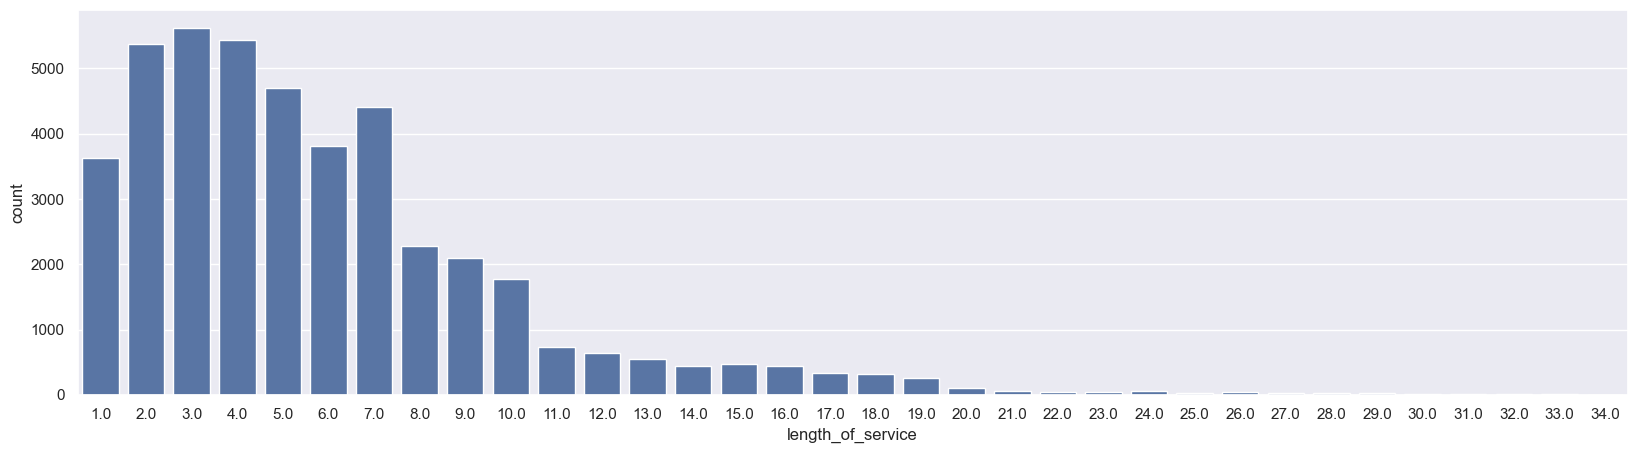

In [167]:
plt.figure(figsize = (20, 5))
sns.countplot(data = X_train_num_imputed, x = 'length_of_service')

In [168]:
#Función clip:
a = np.array([-10,10,20,30,40,50,60,70,1000])
a

array([ -10,   10,   20,   30,   40,   50,   60,   70, 1000])

In [169]:
np.clip(a, 0 , 100)

array([  0,  10,  20,  30,  40,  50,  60,  70, 100])

In [170]:
#Calculamos percentiles:
np.percentile(X_train_num_imputed['length_of_service'], 99)

np.float64(20.0)

In [171]:
np.percentile(X_train_num_imputed['length_of_service'], 0)

np.float64(1.0)

In [172]:
#Resumen - consolidado:

In [173]:
columna ='length_of_service'

p0 = np.percentile(X_train_num_imputed[columna], 0)
p99 = np.percentile(X_train_num_imputed[columna], 99)

In [74]:
#Reemplazo mi columna con el clip:

In [174]:
X_train_num_imputed[columna] = np.clip(X_train_num_imputed[columna], p0, p99)

<Axes: xlabel='length_of_service', ylabel='count'>

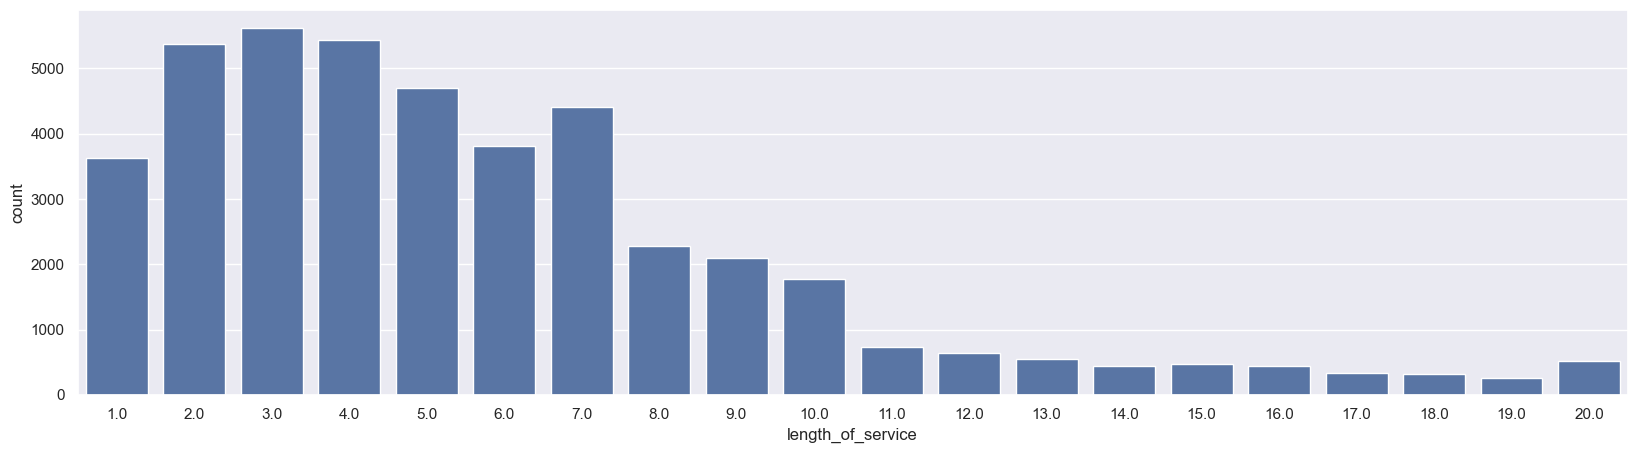

In [177]:
plt.figure(figsize = (20, 5))
sns.countplot(data = X_train_num_imputed, x = 'length_of_service')

In [176]:
X_train_num_imputed.describe(percentiles = np.arange(0.9, 1, 0.01))

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
count,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000,43846.000000
mean,1.251950,34.820873,3.307143,5.824522,0.352050,0.022921,63.383957
std,0.610654,7.673484,1.215935,4.072022,0.477615,0.149654,13.356721
min,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,40.000000
50%,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000
90%,2.000000,46.000000,5.000000,11.000000,1.000000,0.000000,83.000000
91%,2.000000,47.000000,5.000000,12.000000,1.000000,0.000000,84.000000
92%,2.000000,48.000000,5.000000,12.000000,1.000000,0.000000,84.000000
93%,2.000000,49.000000,5.000000,13.000000,1.000000,0.000000,85.000000
94%,2.000000,50.000000,5.000000,14.000000,1.000000,0.000000,85.000000


## Generación de dummies

Aplicamos one hot encoding a las variables categóricas

In [178]:
X_train_cat_imputed.head()

,department,region,education,gender,recruitment_channel
0,Operations,region_15,Bachelor's,m,sourcing
1,Procurement,region_17,Master's & above,f,sourcing
2,Procurement,region_2,Bachelor's,f,other
3,Sales & Marketing,region_13,Bachelor's,m,other
4,Technology,region_20,Master's & above,m,sourcing


In [179]:
pd.get_dummies(X_train_cat_imputed.head())
#4 valores de departamento genera 4 columnas, pero hay información redundante, evidente.

,department_Operations,department_Procurement,department_Sales & Marketing,department_Technology,region_region_13,region_region_15,region_region_17,region_region_2,region_region_20,education_Bachelor's,education_Master's & above,gender_f,gender_m,recruitment_channel_other,recruitment_channel_sourcing
0,True,False,False,False,False,True,False,False,False,True,False,False,True,False,True
1,False,True,False,False,False,False,True,False,False,False,True,True,False,False,True
2,False,True,False,False,False,False,False,True,False,True,False,True,False,True,False
3,False,False,True,False,True,False,False,False,False,True,False,False,True,True,False
4,False,False,False,True,False,False,False,False,True,False,True,False,True,False,True


In [180]:
pd.get_dummies(X_train_cat_imputed.head(), drop_first=True)
#Elimina una columna para cada uno (ejm: genero)

,department_Procurement,department_Sales & Marketing,department_Technology,region_region_15,region_region_17,region_region_2,region_region_20,education_Master's & above,gender_m,recruitment_channel_sourcing
0,False,False,False,True,False,False,False,False,True,True
1,True,False,False,False,True,False,False,True,False,True
2,True,False,False,False,False,True,False,False,False,False
3,False,True,False,False,False,False,False,False,True,False
4,False,False,True,False,False,False,True,True,True,True


In [81]:
#Ahora si generamos nuestras variables en una sola línea:

In [181]:
X_train_cat_dummies = pd.get_dummies(X_train_cat_imputed, drop_first=True)

In [182]:
X_train_cat_dummies.head()

,department_Finance,department_HR,department_Legal,department_Operations,department_Procurement,department_R&D,department_Sales & Marketing,department_Technology,region_region_10,region_region_11,...,region_region_5,region_region_6,region_region_7,region_region_8,region_region_9,education_Below Secondary,education_Master's & above,gender_m,recruitment_channel_referred,recruitment_channel_sourcing
0,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
1,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True
2,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,True,True,False,True


## Consolidación

In [84]:
#Como al inicio separamos nuestras numéricas de las categóricas para hacer el preprocesamiento, ahora las unimos:

In [183]:
X_train_total = pd.concat([X_train_num_imputed, X_train_cat_dummies], axis = 1)

In [184]:
X_train_total.shape

(43846, 53)

In [185]:
X_train_total.head(2)

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,department_Finance,department_HR,department_Legal,...,region_region_5,region_region_6,region_region_7,region_region_8,region_region_9,education_Below Secondary,education_Master's & above,gender_m,recruitment_channel_referred,recruitment_channel_sourcing
0,1.0,39.0,5.0,4.0,1.0,0.0,59.0,False,False,False,...,False,False,False,False,False,False,False,True,False,True
1,1.0,47.0,3.0,3.0,0.0,0.0,67.0,False,False,False,...,False,False,False,False,False,False,True,False,False,True


## Escalamiento

In [88]:
#Se está utilizando el MinMaxScaler, que ajusta los valores de cada característica para que estén entre 0 y 1, 
#lo que facilita el trabajo de algunos algoritmos que son sensibles a la escala de los datos

In [186]:
from sklearn.preprocessing import MinMaxScaler

In [187]:
scaler = MinMaxScaler()

In [188]:
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_total), columns = X_train_total.columns)
X_train_scaled.head(2)

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,department_Finance,department_HR,department_Legal,...,region_region_5,region_region_6,region_region_7,region_region_8,region_region_9,education_Below Secondary,education_Master's & above,gender_m,recruitment_channel_referred,recruitment_channel_sourcing
0,0.0,0.475,1.0,0.157895,1.0,0.0,0.322034,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,0.0,0.675,0.5,0.105263,0.0,0.0,0.457627,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [189]:
X_train_scaled.shape

(43846, 53)

## Replicar el preprocesamiento en la data de test

In [190]:
X_test.shape

(10962, 12)

In [191]:
X_test.head()

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
9351,Procurement,region_23,Bachelor's,m,other,1,27,4.0,2,0,0,69
7289,Procurement,region_15,Master's & above,m,other,1,45,3.0,18,0,0,67
22339,Analytics,region_32,Bachelor's,m,other,2,36,2.0,3,0,0,82
23422,Technology,region_1,Bachelor's,f,sourcing,1,28,5.0,5,1,0,75
36639,Sales & Marketing,region_7,Bachelor's,f,sourcing,1,34,2.0,10,1,0,52


imputación

In [192]:
X_test_num = X_test.select_dtypes('number')
X_test_cat = X_test.select_dtypes('object')

In [193]:
X_test_num_imputed = imputer_num.transform(X_test_num)
X_test_cat_imputed = imputer_cat.transform(X_test_cat)

In [194]:
X_test_num_imputed = pd.DataFrame(data = X_test_num_imputed, columns = X_test_num.columns)
X_test_cat_imputed = pd.DataFrame(data = X_test_cat_imputed, columns = X_test_cat.columns)

Capeo de outliers

In [195]:
columna = 'length_of_service'

X_test_num_imputed[columna] = np.clip(X_test_num_imputed[columna], p0, p99)

Generación de dummies

In [196]:
X_test_cat_dummies = pd.get_dummies(X_test_cat_imputed, drop_first=True)

Consolidación

In [197]:
X_test_total = pd.concat([X_test_num_imputed, X_test_cat_dummies], axis = 1)

Escalamiento

In [198]:
X_test_scaled = pd.DataFrame(data = scaler.transform(X_test_total), columns = X_test_total.columns)
X_test_scaled.head()

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,department_Finance,department_HR,department_Legal,...,region_region_5,region_region_6,region_region_7,region_region_8,region_region_9,education_Below Secondary,education_Master's & above,gender_m,recruitment_channel_referred,recruitment_channel_sourcing
0,0.000000,0.175,0.75,0.052632,0.0,0.0,0.491525,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.000000,0.625,0.50,0.894737,0.0,0.0,0.457627,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2,0.111111,0.400,0.25,0.105263,0.0,0.0,0.711864,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.000000,0.200,1.00,0.210526,1.0,0.0,0.593220,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.000000,0.350,0.25,0.473684,1.0,0.0,0.203390,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [199]:
X_test_scaled.shape

(10962, 53)

## Guardar datasets preprocesados

Creación de copias de los datasets preprocesados:
X_train_export y X_test_export son copias de los datasets escalados (preprocesados). La razón para hacer esto es que, si más adelante necesitas hacer modificaciones a los datos, tienes una copia separada para trabajar con ella sin afectar el dataset original.

In [204]:
X_train_export = X_train_scaled.copy()
X_test_export = X_test_scaled.copy()

In [205]:
from pathlib import Path

desktop = Path.home() / "Desktop"

X_train_export.to_csv(desktop / "preprocessed_train.csv", index=False)
X_test_export.to_csv(desktop / "preprocessed_test.csv", index=False)

Agregar la columna del objetivo (target):Agregando la columna objetivo (el target o etiqueta) a los datasets de entrenamiento y prueba, respectivamente.

In [206]:
X_train_export[target] = y_train.values
X_test_export[target] = y_test.values

Guardar los datasets en formato CSV:

In [ ]:
X_train_export.to_csv('preprocessed_train.csv', index = False)
X_test_export.to_csv('preprocessed_test.csv', index = False)


In [ ]:
#Puedo entrenar con el train de esta data y probar en su test

## Balanceo

In [209]:
import imblearn

In [210]:
imblearn.__version__

'0.14.0'

In [211]:
y_train.value_counts()

is_promoted
0    40112
1     3734
Name: count, dtype: int64

In [212]:
y_train.mean()
#Una tasa del 8% -> Buscamos un 20/25% para que este mejor representando la cantidad de "1"

np.float64(0.08516170232176254)

In [213]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

In [214]:
ros = RandomOverSampler(sampling_strategy = 0.25)

In [313]:
X_ros, y_ros = ros.fit_resample(X_train_scaled, y_train)

In [216]:
y_train.value_counts()

is_promoted
0    40112
1     3734
Name: count, dtype: int64

In [218]:
y_ros.value_counts()

is_promoted
0    40112
1    10028
Name: count, dtype: int64

### Exportar datasets balanceados

Se está creando una copia de este dataset balanceado para trabajar con ella sin modificar el dataset original. La razón para hacer una copia es que, en muchos casos, puedes querer mantener el original intacto por si necesitas volver a él más adelante.

In [ ]:
X_train_ros_export = X_ros.copy()
X_train_ros_export[target] = y_ros.values

X_train_ros_export.to_csv('preprocessed_train_20.csv', index=False)


In [ ]:
#Luego puedo entrenar el modelo con esta data de train y probar con el test de líneas arriba (antes de balancear)

PROYECTO FINAL - GRUPO 2 (POTENCIAR EL PRE PROCESAMIENTO)

In [222]:
import pandas as pd

train = pd.read_csv("./preprocessed_train.csv")
test = pd.read_csv("./preprocessed_test.csv")

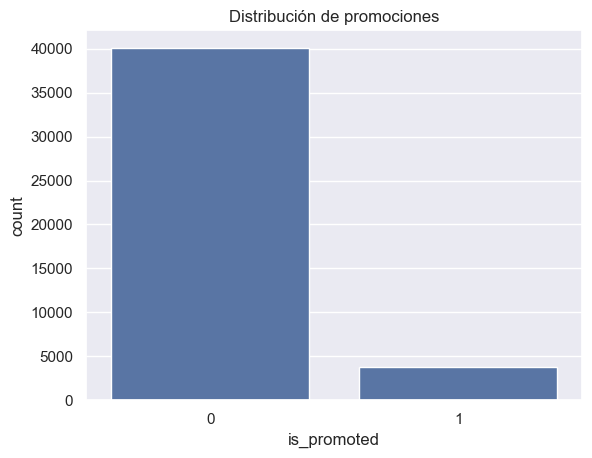

In [223]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='is_promoted', data=train)

plt.title('Distribución de promociones')
plt.show()

In [ ]:
#Se evaluó la distribución de la variable objetivo "is_promoted". Se observó un desbalance significativo entre clases, donde aproximadamente el 91.5% de los trabajadores no fueron promovidos y solo el 8.5% fueron promovidos.

In [ ]:
corr_target = train.corr()['is_promoted']

corr_target.abs().sort_values(
    ascending=False
).head(10)


In [ ]:
#La correlación varía entre -1 y 1:
#Cercano a 1 → relación positiva fuerte. 
#Cercano a 0 → poca o ninguna relación. 
#Cercano a -1 → relación negativa fuerte.

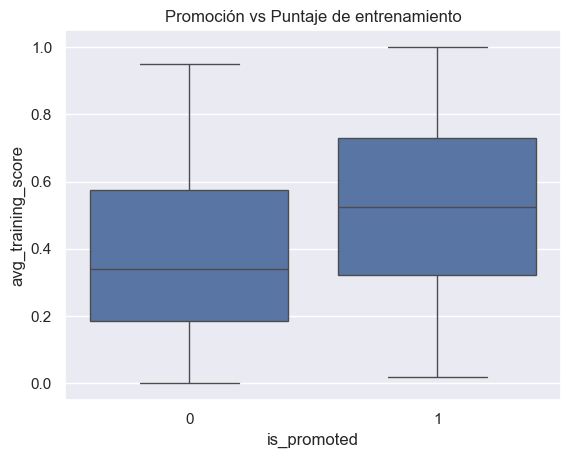

In [225]:
sns.boxplot(
    x='is_promoted',
    y='avg_training_score',
    data=train
)
plt.title("Promoción vs Puntaje de entrenamiento")
plt.show()


In [226]:
#Los trabajadores promovidos presentan, en promedio, mayores puntajes de capacitación que aquellos que no fueron promovidos.

In [234]:
train.groupby('is_promoted')['avg_training_score'].mean()

is_promoted
0    0.384188
1    0.526863
Name: avg_training_score, dtype: float64

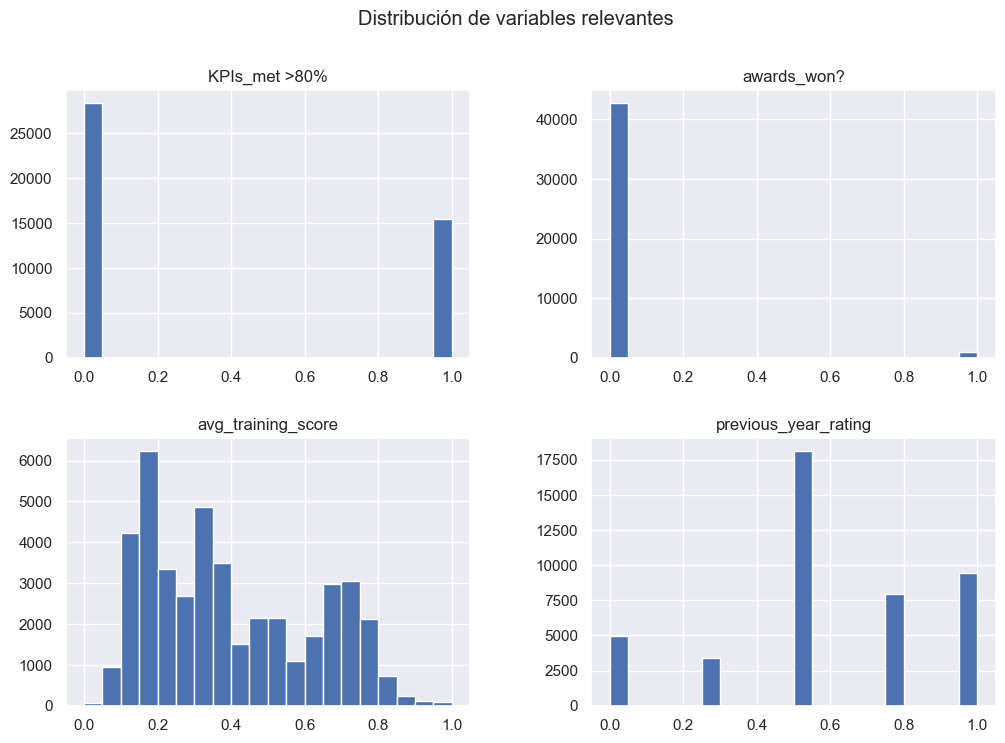

In [228]:
variables = [
    'KPIs_met >80%',
    'awards_won?',
    'avg_training_score',
    'previous_year_rating'
]

train[variables].hist(
    figsize=(12,8),
    bins=20
)

plt.suptitle("Distribución de variables relevantes")
plt.show()

In [236]:
corr = train.corr()
corr

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,department_Finance,department_HR,department_Legal,...,region_region_6,region_region_7,region_region_8,region_region_9,education_Below Secondary,education_Master's & above,gender_m,recruitment_channel_referred,recruitment_channel_sourcing,is_promoted
no_of_trainings,1.000000,-0.079855,-0.062816,-0.057404,-0.047632,-0.004794,0.045424,0.018287,-0.070352,-0.036452,...,-0.014990,0.006367,-0.033761,0.001085,0.002454,-0.033929,0.086846,-0.013465,-0.007552,-0.022584
age,-0.079855,1.000000,0.026816,0.657799,-0.025285,-0.011161,-0.050243,-0.075148,-0.010478,-0.018619,...,-0.060313,0.037401,-0.045366,-0.059836,-0.172225,0.361872,-0.014974,-0.043792,-0.002952,-0.017816
previous_year_rating,-0.062816,0.026816,1.000000,0.024493,0.335623,0.021473,0.069218,0.028226,0.021753,-0.001308,...,-0.017019,0.019505,0.006086,-0.034627,-0.000262,0.027776,-0.022330,0.064293,-0.004886,0.151343
length_of_service,-0.057404,0.657799,0.024493,1.000000,-0.078517,-0.040520,-0.039539,-0.052642,-0.008934,-0.040735,...,-0.040390,0.029639,-0.032765,-0.042358,-0.121175,0.255018,-0.018938,-0.031089,0.003456,-0.010570
KPIs_met >80%,-0.047632,-0.025285,0.335623,-0.078517,1.000000,0.097702,0.075870,0.027056,-0.007760,-0.003494,...,-0.011013,0.003973,0.012288,-0.030266,0.013031,0.011423,-0.037255,0.046059,-0.008685,0.222140
awards_won?,-0.004794,-0.011161,0.021473,-0.040520,0.097702,1.000000,0.069889,0.005311,-0.007168,0.001569,...,-0.001933,-0.002531,0.000731,-0.001640,-0.002963,-0.001734,0.008144,-0.001037,-0.006402,0.192963
avg_training_score,0.045424,-0.050243,0.069218,-0.039539,0.075870,0.069889,1.000000,-0.052119,-0.215545,-0.034954,...,-0.023832,0.010747,0.000156,-0.015132,0.015662,0.031456,-0.026265,0.032154,-0.006800,0.175913
department_Finance,0.018287,-0.075148,0.028226,-0.052642,0.027056,0.005311,-0.052119,1.000000,-0.047608,-0.030312,...,0.005772,-0.000302,-0.009068,-0.011147,0.046691,-0.035831,0.007970,-0.028425,-0.003399,0.000237
department_HR,-0.070352,-0.010478,0.021753,-0.008934,-0.007760,-0.007168,-0.215545,-0.047608,1.000000,-0.029635,...,-0.014091,0.006939,-0.014186,-0.019269,0.066551,0.014713,-0.051040,0.031196,-0.015486,-0.021826
department_Legal,-0.036452,-0.018619,-0.001308,-0.040735,-0.003494,0.001569,-0.034954,-0.030312,-0.029635,1.000000,...,-0.006159,0.003261,-0.012340,-0.008450,0.049194,-0.036631,0.045472,-0.008219,-0.001090,-0.016456


In [ ]:
# Al observar muchas variables que no aportarán en la gráfica de correlación (Mapa de calor) se borrará las variables de tipo "región"

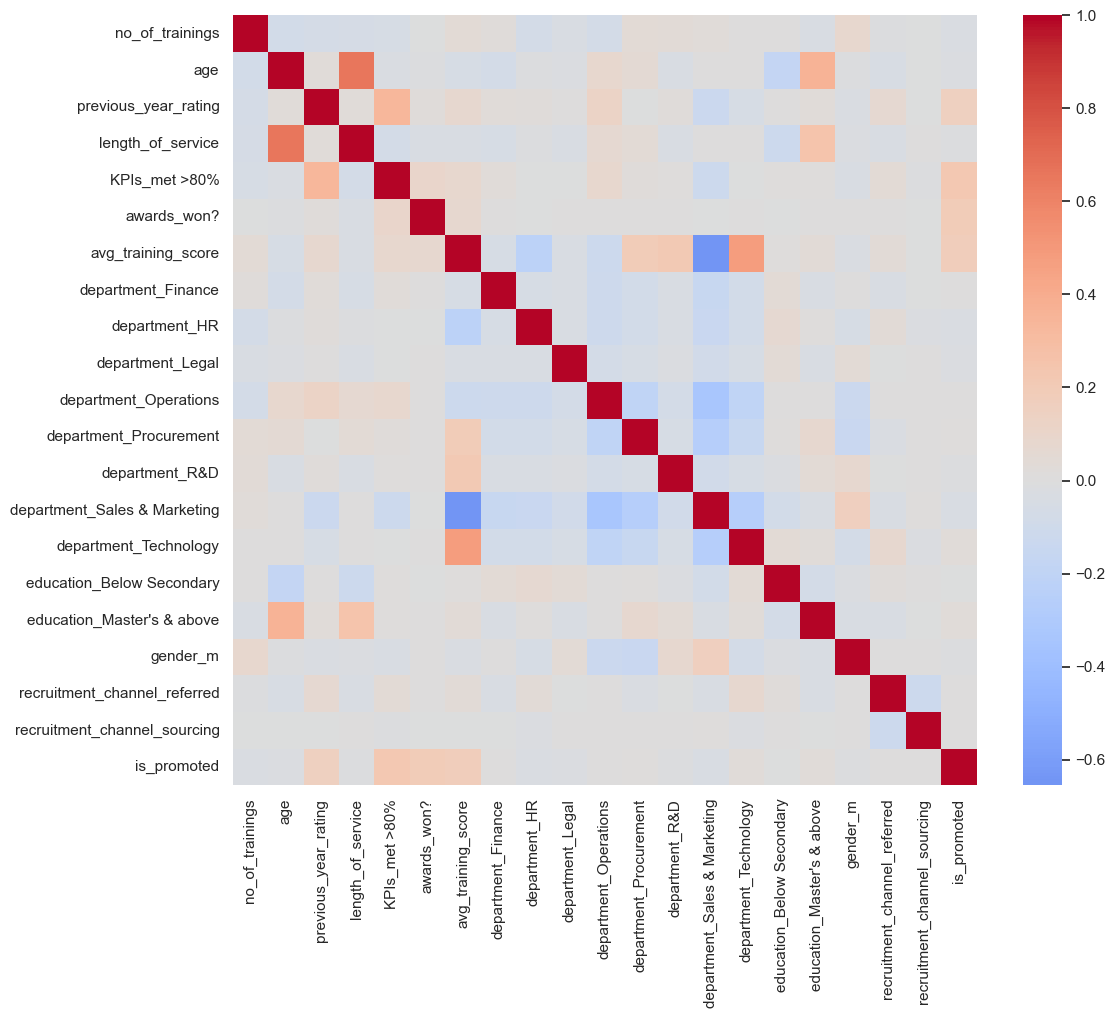

In [237]:
columnas_sin_region = corr.columns[~corr.columns.str.contains('region')]
corr_filtrada = corr.loc[columnas_sin_region, columnas_sin_region]

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_filtrada,  # <--- Usamos la matriz limpia aquí
    cmap='coolwarm',
    center=0
)

plt.show()

In [238]:
corr = train.corr(numeric_only=True)

corr_pairs = corr.unstack()

corr_pairs = corr_pairs[
    corr_pairs != 1
]

corr_pairs.abs().sort_values(
    ascending=False
).head(20)

length_of_service             age                             0.657799
age                           length_of_service               0.657799
avg_training_score            department_Sales & Marketing    0.655132
department_Sales & Marketing  avg_training_score              0.655132
avg_training_score            department_Technology           0.480066
department_Technology         avg_training_score              0.480066
education_Master's & above    age                             0.361872
age                           education_Master's & above      0.361872
department_Operations         department_Sales & Marketing    0.339714
department_Sales & Marketing  department_Operations           0.339714
previous_year_rating          KPIs_met >80%                   0.335623
KPIs_met >80%                 previous_year_rating            0.335623
region_region_2               age                             0.284241
age                           region_region_2                 0.284241
depart

MODELAMIENTO

In [239]:
X_train = train.drop(
    columns=['is_promoted']
)

y_train = train['is_promoted']

X_test = test.drop(
    columns=['is_promoted']
)

y_test = test['is_promoted']

In [240]:
from sklearn.linear_model import LogisticRegression

modelo_lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

modelo_lr.fit(
    X_train,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [241]:
y_pred_lr = modelo_lr.predict(
    X_test
)

In [280]:
from sklearn.tree import DecisionTreeClassifier

modelo_tree = DecisionTreeClassifier(
    criterion='gini',         
    max_depth=5,              # Un nivel un poco más profundo, controlado
    min_samples_split=20,     # Evita divisiones con pocos datos
    min_samples_leaf=10,      # Evita que las hojas finales sean demasiado pequeñas
    class_weight='balanced',  # Crítico para la variable target "promoted" desbalanceada
    random_state=42
)

modelo_tree.fit(
    X_train,
    y_train
)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,20
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [281]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score

In [282]:
from sklearn.metrics import accuracy_score

accuracy_score(
    y_test,
    y_pred_lr
)

0.9328589673417259

In [283]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [284]:
#Regresión logística

In [285]:
y_pred_lr = modelo_lr.predict(X_test)

y_prob_lr = modelo_lr.predict_proba(X_test)[:,1]

In [286]:
print(classification_report(
    y_test,
    y_pred_lr
))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96     10028
           1       0.89      0.24      0.38       934

    accuracy                           0.93     10962
   macro avg       0.91      0.62      0.67     10962
weighted avg       0.93      0.93      0.91     10962



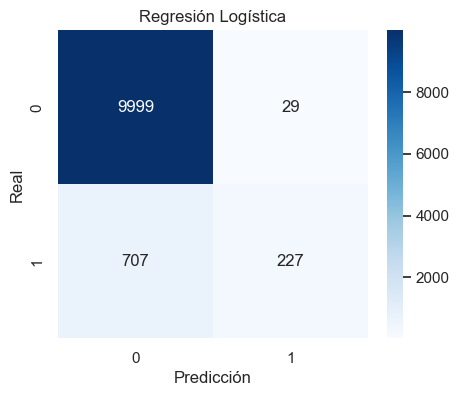

In [287]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Regresión Logística')
plt.ylabel('Real')
plt.xlabel('Predicción')

plt.show()

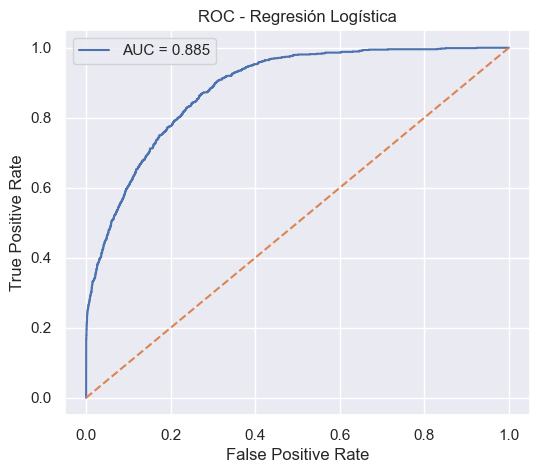

In [288]:
fpr, tpr, _ = roc_curve(
    y_test,
    y_prob_lr
)

auc_lr = roc_auc_score(
    y_test,
    y_prob_lr
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f'AUC = {auc_lr:.3f}'
)

plt.plot(
    [0,1],
    [0,1],
    '--'
)

plt.title('ROC - Regresión Logística')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

In [289]:
#Arbol de decisión

In [290]:
y_pred_tree = modelo_tree.predict(X_test)

y_prob_tree = modelo_tree.predict_proba(X_test)[:,1]

In [291]:
print(classification_report(
    y_test,
    y_pred_tree
))

              precision    recall  f1-score   support

           0       0.98      0.67      0.80     10028
           1       0.20      0.89      0.33       934

    accuracy                           0.69     10962
   macro avg       0.59      0.78      0.56     10962
weighted avg       0.92      0.69      0.76     10962



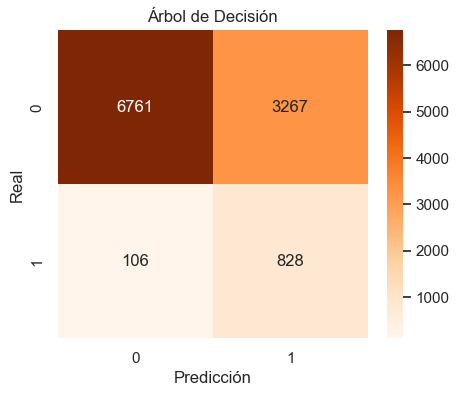

In [292]:
cm = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title('Árbol de Decisión')
plt.ylabel('Real')
plt.xlabel('Predicción')

plt.show()

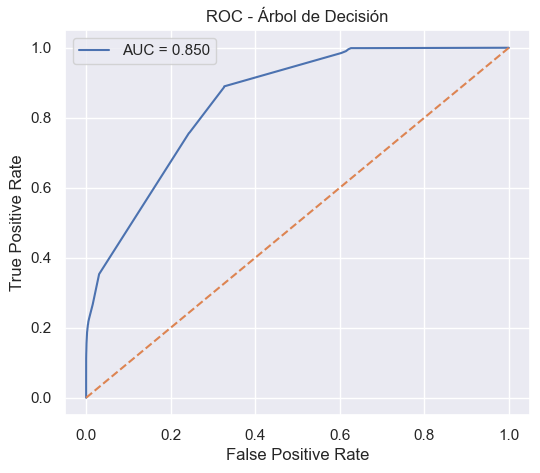

In [293]:
fpr, tpr, _ = roc_curve(
    y_test,
    y_prob_tree
)

auc_tree = roc_auc_score(
    y_test,
    y_prob_tree
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f'AUC = {auc_tree:.3f}'
)

plt.plot(
    [0,1],
    [0,1],
    '--'
)

plt.title('ROC - Árbol de Decisión')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

In [294]:
import pandas as pd

importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': modelo_tree.feature_importances_
})

importancias = importancias.sort_values(
    by='Importancia',
    ascending=False
)

importancias.head(10)

,Variable,Importancia
4,KPIs_met >80%,0.359560
6,avg_training_score,0.272420
13,department_Sales & Marketing,0.158112
2,previous_year_rating,0.130919
5,awards_won?,0.056085
8,department_HR,0.009633
10,department_Operations,0.007086
3,length_of_service,0.003076
1,age,0.001641
26,region_region_20,0.000936


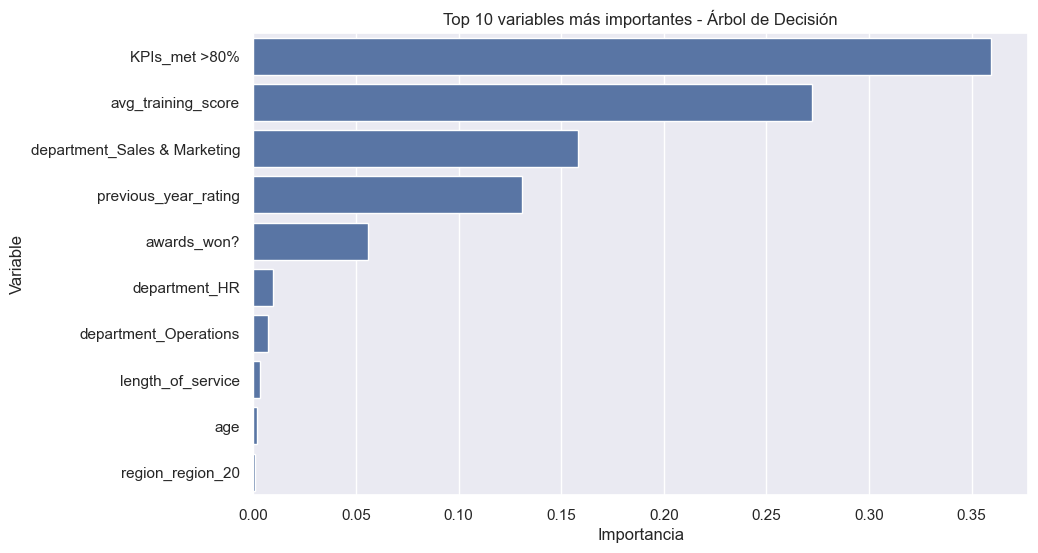

In [295]:
import seaborn as sns
import matplotlib.pyplot as plt

top10 = importancias.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10,
    x='Importancia',
    y='Variable'
)

plt.title('Top 10 variables más importantes - Árbol de Decisión')

plt.show()

In [ ]:
# Se concluye que las variables KPIs_met > 80% y avg_training score son las variables más importantes del Árbol de deciisón,
# acumulando más del 63% de la relevancia del modelo

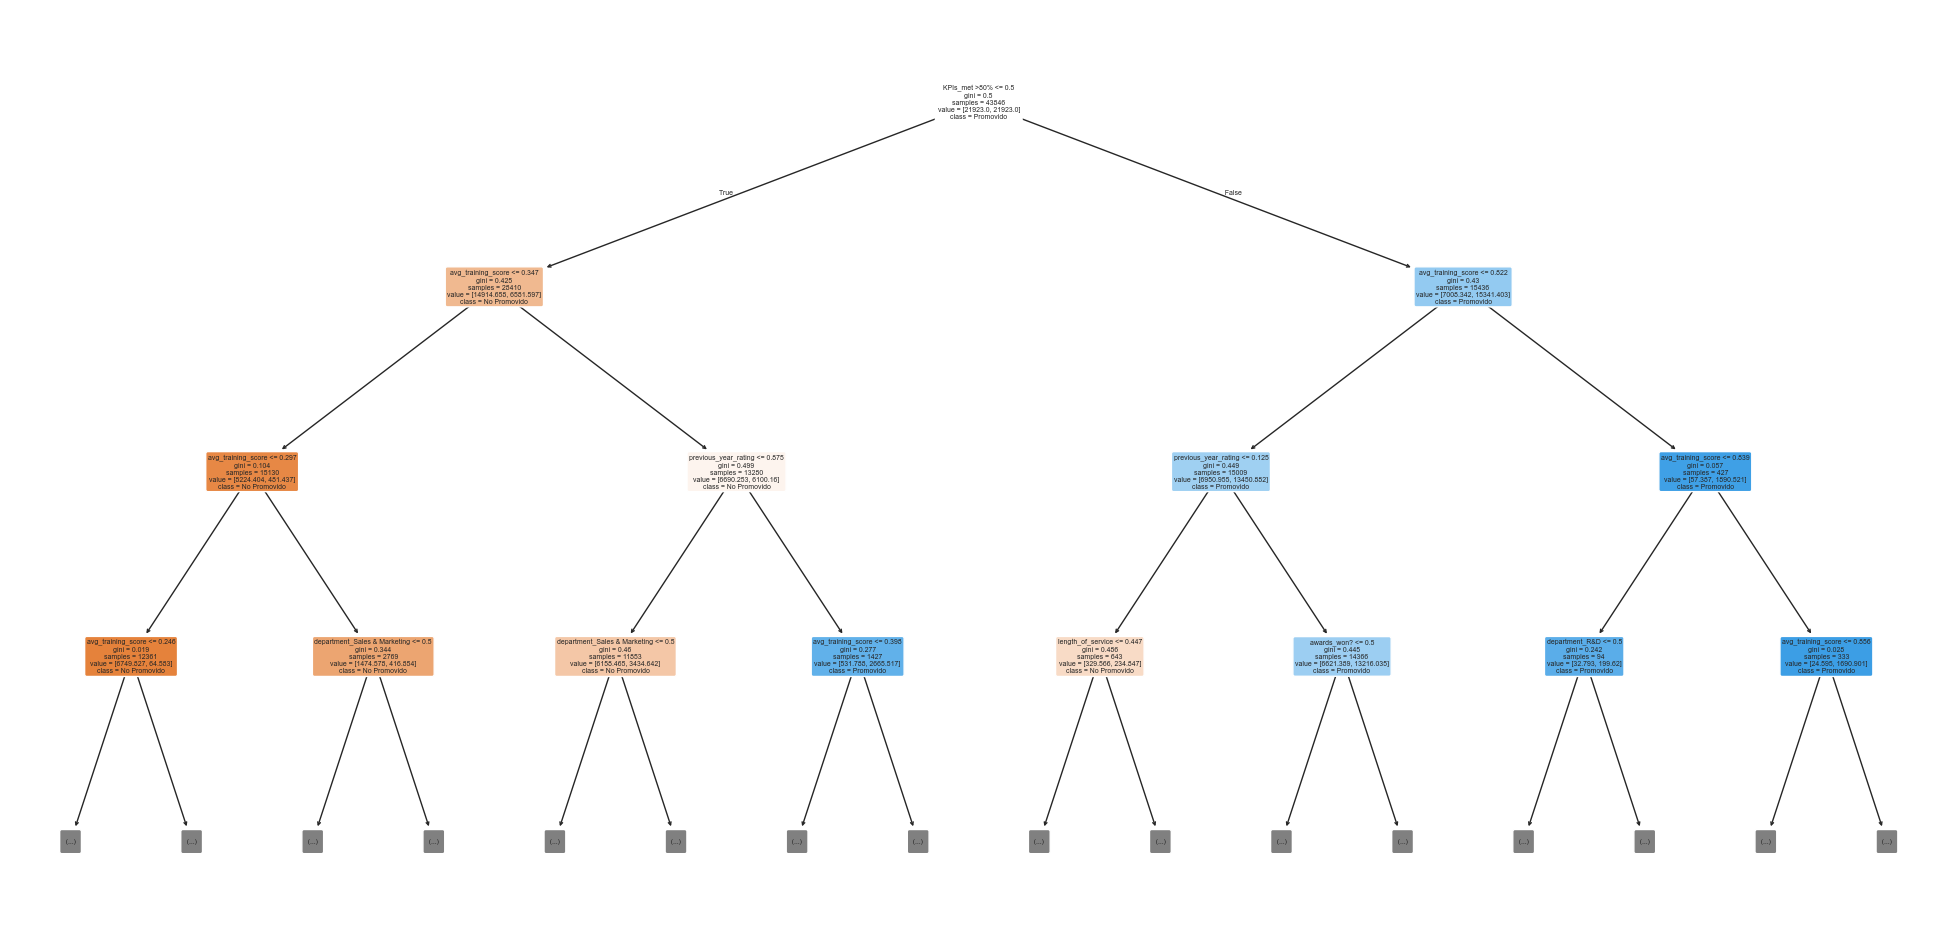

In [296]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(25,12))

plot_tree(
    modelo_tree,
    feature_names=X_train.columns,
    class_names=['No Promovido','Promovido'],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.savefig(
    "arbol_decision.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [297]:
#Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_train, y_train)


In [ ]:
y_pred_rf = modelo_rf.predict(X_test)

y_prob_rf = modelo_rf.predict_proba(X_test)[:,1]

In [301]:
print(classification_report(
    y_test,
    y_pred_rf
))

              precision    recall  f1-score   support

           0       0.94      0.99      0.97     10028
           1       0.86      0.33      0.47       934

    accuracy                           0.94     10962
   macro avg       0.90      0.66      0.72     10962
weighted avg       0.93      0.94      0.93     10962



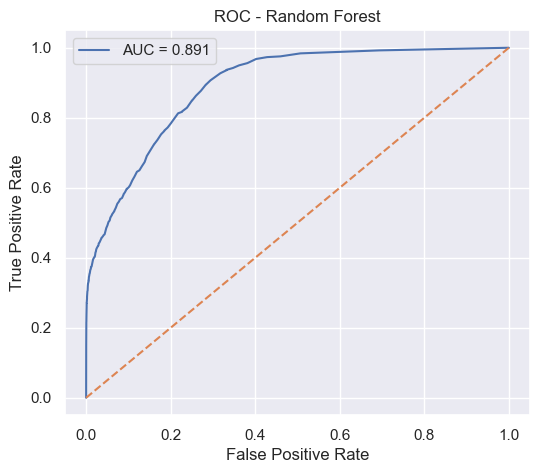

In [304]:
fpr, tpr, _ = roc_curve(
    y_test,
    y_prob_rf
)

auc_rf = roc_auc_score(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f'AUC = {auc_rf:.3f}'
)

plt.plot(
    [0,1],
    [0,1],
    '--'
)

plt.title('ROC - Random Forest')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

In [306]:
resultados = pd.DataFrame({

'Modelo':[
    'Regresión Logística',
    'Árbol de Decisión',
    'Random Forest'
],

'Accuracy':[
    accuracy_score(y_test,y_pred_lr),
    accuracy_score(y_test,y_pred_tree),
    accuracy_score(y_test,y_pred_rf)
],

'Precision Clase 1':[
    precision_score(y_test,y_pred_lr),
    precision_score(y_test,y_pred_tree),
    precision_score(y_test,y_pred_rf)
],

'Recall Clase 1':[
    recall_score(y_test,y_pred_lr),
    recall_score(y_test,y_pred_tree),
    recall_score(y_test,y_pred_rf)
],

'F1 Clase 1':[
    f1_score(y_test,y_pred_lr),
    f1_score(y_test,y_pred_tree),
    f1_score(y_test,y_pred_rf)
],

'AUC':[
    auc_lr,
    auc_tree,
    auc_rf
]

})

resultados.sort_values(
    by='F1 Clase 1',
    ascending=False
)

,Modelo,Accuracy,Precision Clase 1,Recall Clase 1,F1 Clase 1,AUC
2,Random Forest,0.938059,0.855153,0.328694,0.474865,0.891191
0,Regresión Logística,0.932859,0.886719,0.243041,0.381513,0.885030
1,Árbol de Decisión,0.692301,0.202198,0.886510,0.329290,0.850190


Los resultados mostraron que el modelo Random Forest obtuvo el mejor desempeño general, alcanzando una exactitud de 93.8%, un Recall de 32.9% para la clase promovida, un F1-Score de 0.475 y un AUC de 0.891. Por su parte, la Regresión Logística obtuvo resultados aceptables, aunque con una menor capacidad para identificar trabajadores promovidos. 

# PASO 3 — MODELADO CON DATOS BALANCEADOS

En esta sección se entrena con tres estrategias de balanceo:
- **Oversampling** (`RandomOverSampler`)
- **Undersampling** (`RandomUnderSampler`)
- **SMOTE** (Synthetic Minority Over-sampling Technique) — genera muestras sintéticas interpolando entre observaciones minoritarias existentes, en lugar de simplemente duplicarlas como hace el oversampling aleatorio.

Todos los modelos se validan con el **mismo test sin balancear**, garantizando una evaluación realista.

In [324]:
# # Lectura de datos preprocesados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

# Configuración de la semilla del sistema
seed = 42 

train_bal = pd.read_csv("./preprocessed_train_20.csv")
test_bal   = pd.read_csv("./preprocessed_test.csv")

target = 'is_promoted'

X_train_bal = train_bal.drop(columns=[target])
y_train_bal = train_bal[target]

X_test_bal = test_bal.drop(columns=[target])
y_test_bal  = test_bal[target]

print("Train balanceado shape:", X_train_bal.shape, "| Proporción target:", round(y_train_bal.mean(), 4))
print("Test shape            :", X_test_bal.shape,  "| Proporción target:", round(y_test_bal.mean(), 4))

# El algoritmo se inicializará y creará las variables en memoria
smote = SMOTE(sampling_strategy='auto', random_state=seed, k_neighbors=5)
X_smote, y_smote = smote.fit_resample(X_train_bal, y_train_bal)

Train balanceado shape: (50140, 53) | Proporción target: 0.2
Test shape            : (10962, 53) | Proporción target: 0.0852


## Distribución del target antes y después del balanceo

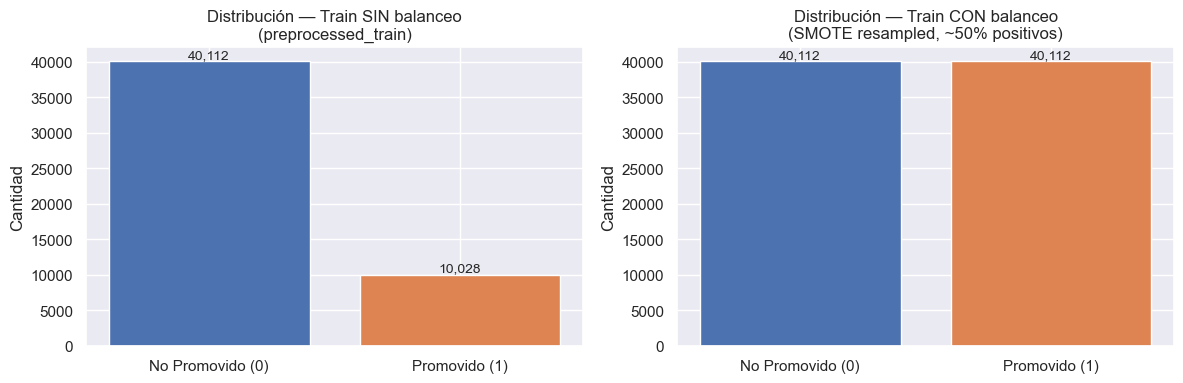

In [325]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- GRÁFICO 1: SIN BALANCEO 
axes[0].bar(['No Promovido (0)', 'Promovido (1)'],
            train_bal[target].value_counts().sort_index(),
            color=['#4C72B0', '#DD8452'])
axes[0].set_title('Distribución — Train SIN balanceo\n(preprocessed_train)')
axes[0].set_ylabel('Cantidad')
for bar in axes[0].patches:
    axes[0].annotate(f'{int(bar.get_height()):,}',
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom', fontsize=10)

# --- GRÁFICO 2: CON BALANCEO (Líneas corregidas) ---
axes[1].bar(['No Promovido (0)', 'Promovido (1)'],
            pd.Series(y_smote).value_counts().sort_index(), # <--- CAMBIO AQUÍ: Usamos y_smote en vez de y_train_bal
            color=['#4C72B0', '#DD8452'])
axes[1].set_title('Distribución — Train CON balanceo\n(SMOTE resampled, ~50% positivos)') 
axes[1].set_ylabel('Cantidad')
for bar in axes[1].patches:
    axes[1].annotate(f'{int(bar.get_height()):,}',
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## Aplicación de tres métodos de balanceo sobre el train balanceado

Se aplican los tres métodos de balanceo sobre el dataset `preprocessed_train_20.csv` (que ya fue generado con oversampling a 50% de positivos). De esta manera podemos comparar los tres enfoques en igualdad de condiciones.

In [327]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

seed = 42

# --- 1. RandomOverSampler ---
# Duplica aleatoriamente registros de la clase minoritaria hasta igualar la mayoritaria
ros = RandomOverSampler(sampling_strategy='auto', random_state=seed)
X_ros, y_ros = ros.fit_resample(X_train_bal, y_train_bal)

# --- 2. RandomUnderSampler ---
# Elimina aleatoriamente registros de la clase mayoritaria hasta igualar la minoritaria
rus = RandomUnderSampler(sampling_strategy='auto', random_state=seed)
X_rus, y_rus = rus.fit_resample(X_train_bal, y_train_bal)

# --- 3. SMOTE ---
# Crea registros sintéticos basados en vecinos cercanos hasta igualar la mayoritaria
smote = SMOTE(sampling_strategy='auto', random_state=seed, k_neighbors=5)
X_smote, y_smote = smote.fit_resample(X_train_bal, y_train_bal)

print("Oversampling  — X shape:", X_ros.shape,   "| % target:", round(y_ros.mean(), 4))
print("Undersampling — X shape:", X_rus.shape,   "| % target:", round(y_rus.mean(), 4))
print("SMOTE         — X shape:", X_smote.shape, "| % target:", round(y_smote.mean(), 4))

Oversampling  — X shape: (80224, 53) | % target: 0.5
Undersampling — X shape: (20056, 53) | % target: 0.5
SMOTE         — X shape: (80224, 53) | % target: 0.5


## Entrenamiento — Random Forest con cada método de balanceo


  Random Forest + Oversampling
              precision    recall  f1-score   support

           0       0.96      0.93      0.94     10028
           1       0.43      0.53      0.47       934

    accuracy                           0.90     10962
   macro avg       0.69      0.73      0.71     10962
weighted avg       0.91      0.90      0.90     10962



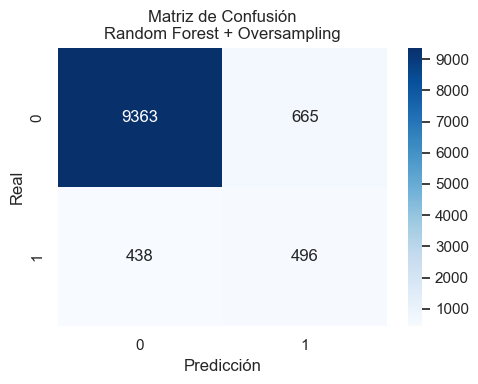


  Random Forest + Undersampling
              precision    recall  f1-score   support

           0       0.98      0.78      0.87     10028
           1       0.26      0.85      0.40       934

    accuracy                           0.78     10962
   macro avg       0.62      0.81      0.63     10962
weighted avg       0.92      0.78      0.83     10962



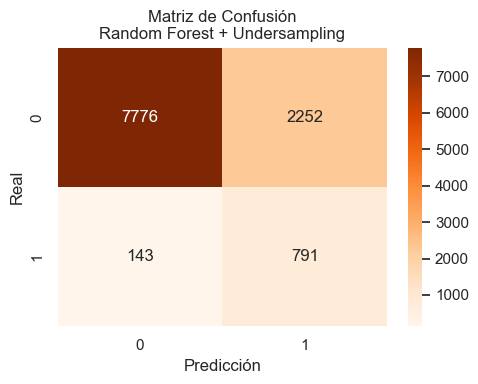


  Random Forest + SMOTE
              precision    recall  f1-score   support

           0       0.96      0.94      0.95     10028
           1       0.45      0.54      0.49       934

    accuracy                           0.91     10962
   macro avg       0.70      0.74      0.72     10962
weighted avg       0.91      0.91      0.91     10962



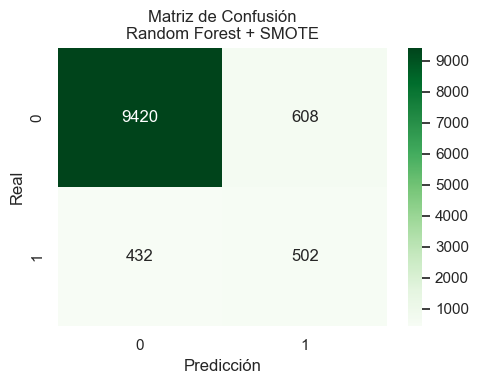

In [328]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)

def entrenar_y_evaluar(X_tr, y_tr, X_te, y_te, nombre, color='Blues'):
    modelo = RandomForestClassifier(
        n_estimators=200, max_depth=50,
        min_samples_split=25, random_state=seed
    )
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)
    y_prob = modelo.predict_proba(X_te)[:, 1]

    print(f"\n{'='*55}")
    print(f"  {nombre}")
    print(f"{'='*55}")
    print(classification_report(y_te, y_pred))

    # Confusion matrix
    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap=color)
    plt.title(f'Matriz de Confusión\n{nombre}')
    plt.ylabel('Real'); plt.xlabel('Predicción')
    plt.tight_layout(); plt.show()

    return modelo, y_pred, y_prob

modelo_ros,   y_pred_ros,   y_prob_ros   = entrenar_y_evaluar(X_ros,   y_ros,   X_test_bal, y_test_bal, "Random Forest + Oversampling",  color='Blues')
modelo_rus,   y_pred_rus,   y_prob_rus   = entrenar_y_evaluar(X_rus,   y_rus,   X_test_bal, y_test_bal, "Random Forest + Undersampling",  color='Oranges')
modelo_smote, y_pred_smote, y_prob_smote = entrenar_y_evaluar(X_smote, y_smote, X_test_bal, y_test_bal, "Random Forest + SMOTE",          color='Greens')

## Curvas ROC — comparación de los tres métodos de balanceo

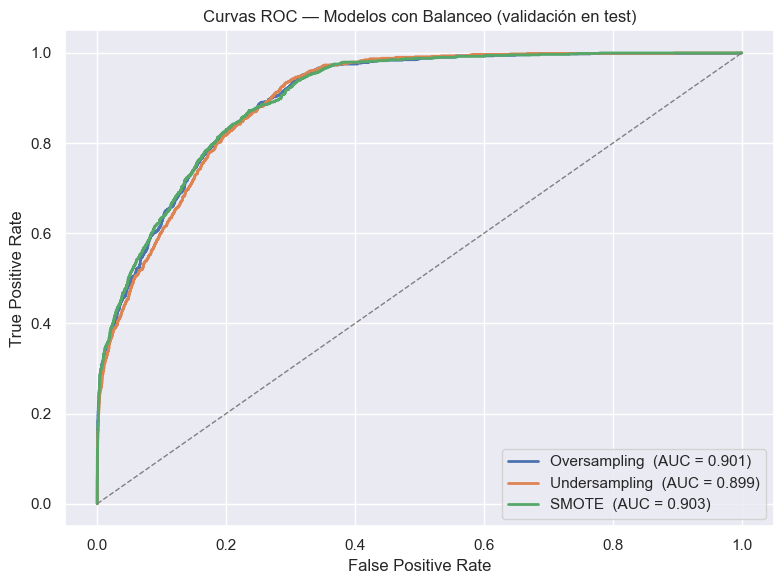

In [329]:
plt.figure(figsize=(8, 6))

for y_prob, nombre, color in [
    (y_prob_ros,   "Oversampling",  "#4C72B0"),
    (y_prob_rus,   "Undersampling", "#DD8452"),
    (y_prob_smote, "SMOTE",         "#55A868"),
]:
    fpr, tpr, _ = roc_curve(y_test_bal, y_prob)
    auc_val = roc_auc_score(y_test_bal, y_prob)
    plt.plot(fpr, tpr, label=f'{nombre}  (AUC = {auc_val:.3f})', color=color, lw=2)

plt.plot([0, 1], [0, 1], '--', color='gray', lw=1)
plt.title('Curvas ROC — Modelos con Balanceo (validación en test)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()

## Tabla comparativa: Sin balanceo vs. Con balanceo

In [330]:
# Resultados del paso anterior (sin balanceo) — se reutilizan las predicciones ya generadas
# Si corriste el notebook de arriba abajo, las variables y_pred_lr, y_pred_tree, y_pred_rf existen
# Si no, descomenta y redefine aquí según sea necesario

resumen = pd.DataFrame({
    'Modelo': [
        'Reg. Logística (sin bal.)',
        'Árbol Decisión (sin bal.)',
        'Random Forest  (sin bal.)',
        'RF + Oversampling',
        'RF + Undersampling',
        'RF + SMOTE',
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test_bal, y_pred_ros),
        accuracy_score(y_test_bal, y_pred_rus),
        accuracy_score(y_test_bal, y_pred_smote),
    ],
    'Precision (clase 1)': [
        precision_score(y_test, y_pred_lr,    zero_division=0),
        precision_score(y_test, y_pred_tree,  zero_division=0),
        precision_score(y_test, y_pred_rf,    zero_division=0),
        precision_score(y_test_bal, y_pred_ros,   zero_division=0),
        precision_score(y_test_bal, y_pred_rus,   zero_division=0),
        precision_score(y_test_bal, y_pred_smote, zero_division=0),
    ],
    'Recall (clase 1)': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test_bal, y_pred_ros),
        recall_score(y_test_bal, y_pred_rus),
        recall_score(y_test_bal, y_pred_smote),
    ],
    'F1 (clase 1)': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test_bal, y_pred_ros),
        f1_score(y_test_bal, y_pred_rus),
        f1_score(y_test_bal, y_pred_smote),
    ],
    'AUC': [
        roc_auc_score(y_test,     modelo_lr.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test,     modelo_tree.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test,     modelo_rf.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test_bal, y_prob_ros),
        roc_auc_score(y_test_bal, y_prob_rus),
        roc_auc_score(y_test_bal, y_prob_smote),
    ],
})

resumen = resumen.sort_values('F1 (clase 1)', ascending=False).reset_index(drop=True)
resumen.round(4)

,Modelo,Accuracy,Precision (clase 1),Recall (clase 1),F1 (clase 1),AUC
0,RF + SMOTE,0.9051,0.4523,0.5375,0.4912,0.9025
1,Random Forest (sin bal.),0.9381,0.8552,0.3287,0.4749,0.8912
2,RF + Oversampling,0.8994,0.4272,0.5310,0.4735,0.9013
3,RF + Undersampling,0.7815,0.2599,0.8469,0.3978,0.8987
4,Reg. Logística (sin bal.),0.9329,0.8867,0.2430,0.3815,0.8850
5,Árbol Decisión (sin bal.),0.6923,0.2022,0.8865,0.3293,0.8502


## Visualización comparativa — F1, Recall y AUC

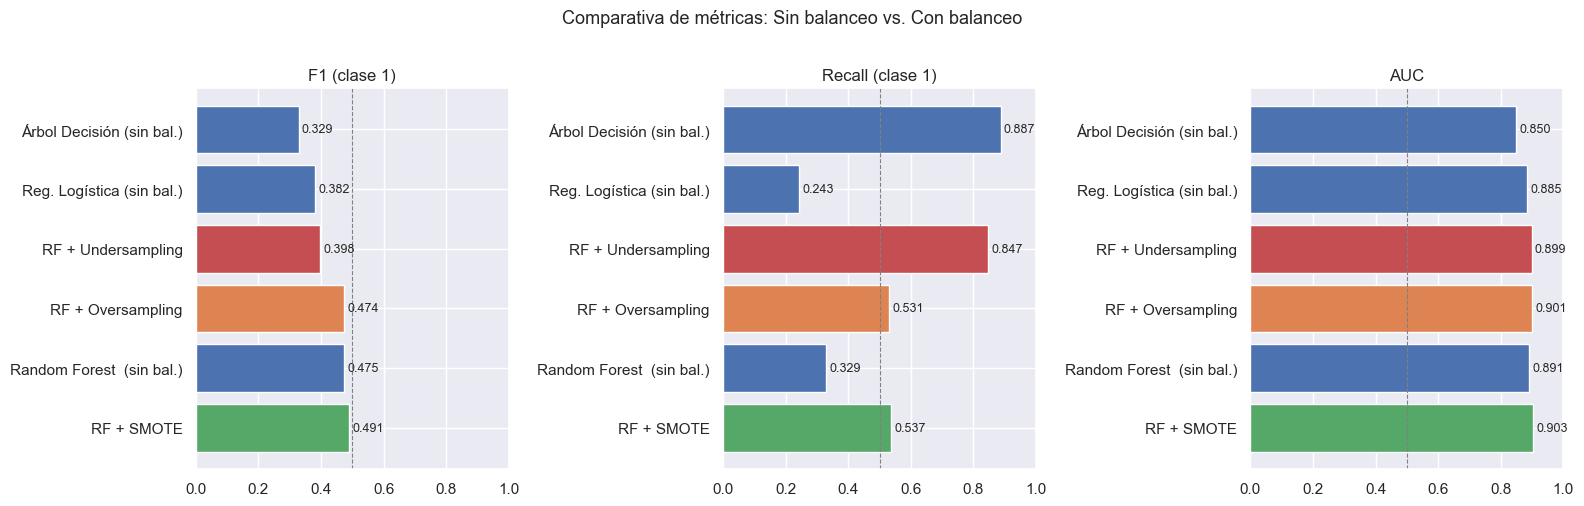

In [331]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colores = ['#4C72B0','#4C72B0','#4C72B0','#DD8452','#55A868','#C44E52']

for ax, metrica in zip(axes, ['F1 (clase 1)', 'Recall (clase 1)', 'AUC']):
    bars = ax.barh(resumen['Modelo'], resumen[metrica],
                   color=['#4C72B0' if 'sin bal' in m else '#DD8452' if 'Over' in m
                          else '#C44E52' if 'Under' in m else '#55A868'
                          for m in resumen['Modelo']])
    ax.set_title(metrica)
    ax.set_xlim(0, 1)
    ax.axvline(0.5, color='gray', linestyle='--', lw=0.8)
    for bar in bars:
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f'{bar.get_width():.3f}', va='center', fontsize=9)

plt.suptitle('Comparativa de métricas: Sin balanceo vs. Con balanceo', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## Conclusiones del Paso 3

- **SMOTE** genera muestras sintéticas interpolando entre puntos de la clase minoritaria usando k-vecinos más cercanos (`k=5`). A diferencia del oversampling aleatorio —que simplemente duplica registros existentes—, SMOTE diversifica el espacio de decisión y suele mejorar la generalización.
- El **Recall** de la clase promovida (`is_promoted = 1`) aumenta de forma significativa con todos los métodos de balanceo, lo cual es deseable cuando el objetivo de negocio es no perder candidatos a promover.
- Existe un **trade-off** entre Precision y Recall: los modelos balanceados identifican más verdaderos positivos pero también generan más falsos positivos.
- El método que logre el **mayor F1-Score** en el test será el recomendado para producción, ya que F1 equilibra ambas métricas. Revisa la tabla comparativa para la decisión final.